# P2.6 · Small CNN on CIFAR-10 (conv/pool/BN, augmentation, OneCycle, early stopping)

**ID:** P2.6 · **Target:** 35 min · **Plan week:** 3 (timed repeat in week 5) · **Part:** P (PyTorch first principles)

**The drill.** Train a small VGG-style CNN on CIFAR-10 (32×32 RGB, 10 classes, 50k train / 10k test) to **≥ 80 % test
accuracy within a few minutes on one GPU**. Hold out a val split, augment on the fly (random crop with padding +
horizontal flip, **train only**), use a one-cycle LR schedule, and early-stop / checkpoint on val.

**Must include (from the plan):** conv/pool/BN, augmentation, LR schedule, early stopping. Also: per-channel
normalization with train statistics, initial-loss check (≈ ln 10), overfit-one-batch, whole-set eval under
`eval()` + `no_grad()`, test touched once.

**Speed design (why it trains in ~1 min, not ~20).** Following Keller Jordan's airbench, the whole dataset lives on
the GPU as one tensor and augmentation is done **per batch on the GPU** (no `DataLoader` workers decoding PIL
images). Training uses bf16 autocast and `channels_last`. The net is conv-BN-ReLU blocks with max-pool (as in airbench's
`ConvGroup`), a global max-pool, and a final logit scale of 1/8 (airbench uses 1/9). The scale shrinks the logits and
their gradients under the large peak LR. It is optional: the measured initial loss is ≈ ln 10 with or without it.
SGD + Nesterov with OneCycle (Smith & Topin) and label smoothing 0.1 (airbench uses 0.2). The
torchvision-transforms + `DataLoader(num_workers=…)` route from the PyTorch tutorial is also fine in an interview.
Say why you chose one or the other.

**Rules.** No docs, no LLM. Data: `torchvision.datasets.CIFAR10(DATA, download=True)` (already in `DATA`; the call
only verifies the md5). Each solution cell keeps only its spec. The self-check names the variables it expects.

## Sources
- A. Krizhevsky, *Learning Multiple Layers of Features from Tiny Images*, Tech. report, U. Toronto, 2009 —
  https://www.cs.toronto.edu/~kriz/learning-features-2009-TR.pdf (CIFAR-10).
- K. Jordan, *94% on CIFAR-10 in 3.29 Seconds on a Single GPU*, 2024, arXiv:2404.00498 — https://arxiv.org/abs/2404.00498;
  code KellerJordan/cifar10-airbench @4c1b6d1, `legacy/airbench94.py`, MIT
  (https://github.com/KellerJordan/cifar10-airbench/blob/4c1b6d1e3889b037efadcfd5c0ea65b246592362/legacy/airbench94.py):
  GPU-resident loader, batch flip/crop, conv-pool-BN-GELU groups, logit scaling, label smoothing. The crop below is
  a simpler gather-based rewrite of its `batch_crop`; nothing else is copied.
- airbench cites D. Page's DAWNBench series *How to train your ResNet* (myrtle.ai, 2018), the origin of the
  GPU-loader + small-net recipe: https://web.archive.org/web/2023/https://myrtle.ai/learn/how-to-train-your-resnet/ (archived; the original URL now 404s)
- PyTorch tutorial *Training a Classifier* (CIFAR-10 with torchvision transforms and DataLoader; BSD-3):
  https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html
- S. Ioffe, C. Szegedy, *Batch Normalization*, ICML 2015, arXiv:1502.03167 — https://arxiv.org/abs/1502.03167
- L. N. Smith, N. Topin, *Super-Convergence: Very Fast Training of Neural Networks Using Large Learning Rates*, 2017,
  arXiv:1708.07120 — https://arxiv.org/abs/1708.07120 (one-cycle policy; `torch.optim.lr_scheduler.OneCycleLR`:
  https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.OneCycleLR.html).
- T. He et al., *Bag of Tricks for Image Classification with Convolutional Neural Networks*, CVPR 2019,
  arXiv:1812.01187 — https://arxiv.org/abs/1812.01187 (label smoothing, warm-up, no weight decay on BN/bias).
- V. Godbole et al., *Deep Learning Tuning Playbook* (2023), "retrospective optimal checkpoint selection",
  google-research/tuning_playbook @7554a51 `README.md`, CC-BY-4.0: https://github.com/google-research/tuning_playbook

In [1]:
import math
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

from prep import DATA, Session, check, check_close, seed_everything

s = Session("P2.6", target_min=35)
seed_everything(0)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
AMP = dict(device_type=dev.type, dtype=torch.bfloat16, enabled=dev.type == "cuda")
CLASSES = ["plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

[P2.6] started 16:57; target 35 min


In [2]:
# 1. DATA. CIFAR10(DATA, train=True/False, download=True). `.data` is uint8 (N, 32, 32, 3) -> float (N, 3, 32, 32) in
#    [0, 1]; `.targets` -> int64. Val = last 5000 of a seeded permutation (generator seed 0) of the 50k train images.
#    Per-CHANNEL mean/std from the 45k train images only -> `mean`, `std` of shape (1, 3, 1, 1).
#    Normalize all splits and move them to `dev`: X_train, y_train, X_val, y_val, X_test, y_test.
tr = torchvision.datasets.CIFAR10(DATA, train=True, download=True)
te = torchvision.datasets.CIFAR10(DATA, train=False, download=True)
to_x = lambda a: torch.tensor(a).permute(0, 3, 1, 2).float().div(255)
X_all, y_all = to_x(tr.data), torch.tensor(tr.targets)
perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(0))
X_train, y_train, X_val, y_val = X_all[perm[:45000]], y_all[perm[:45000]], X_all[perm[45000:]], y_all[perm[45000:]]
mean, std = X_train.mean((0, 2, 3), keepdim=True), X_train.std((0, 2, 3), keepdim=True)
print("train class counts", torch.bincount(y_train).tolist(), "\nmean", mean.flatten().tolist(), "std", std.flatten().tolist())
norm = lambda x: ((x - mean) / std).to(dev)
X_train, X_val, X_test = norm(X_train), norm(X_val), norm(to_x(te.data))
y_train, y_val, y_test = y_train.to(dev), y_val.to(dev), torch.tensor(te.targets).to(dev)
print(X_train.shape, X_train.dtype, X_test.shape)

train class counts [4518, 4492, 4506, 4496, 4468, 4493, 4498, 4494, 4502, 4533] 
mean [0.4911963641643524, 0.48199522495269775, 0.4464317560195923] std [0.24715185165405273, 0.24362300336360931, 0.26167726516723633]


torch.Size([45000, 3, 32, 32]) torch.float32 torch.Size([10000, 3, 32, 32])


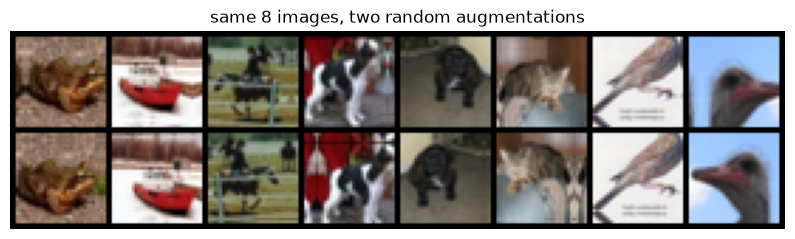

In [3]:
# 2. AUGMENTATION (GPU, per batch, TRAIN ONLY). augment(x, pad=4) for x (B, 3, 32, 32):
#    reflect-pad by 4, then an independent random 32x32 crop PER IMAGE (offsets in [0, 8]), then flip each image
#    horizontally with probability 0.5. Vectorize: build row/col index grids from per-image offsets and gather with
#    advanced indexing (no Python loop over images). Show a few augmented train images.
def augment(x, pad=4):
    B, C, H, W = x.shape
    xp = F.pad(x, (pad,) * 4, mode="reflect")
    i = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    j = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    rows = (i[:, None] + torch.arange(H, device=x.device))[:, None, :, None]   # (B, 1, H, 1)
    cols = (j[:, None] + torch.arange(W, device=x.device))[:, None, None, :]   # (B, 1, 1, W)
    b = torch.arange(B, device=x.device)[:, None, None, None]
    c = torch.arange(C, device=x.device)[None, :, None, None]
    out = xp[b, c, rows, cols]                                                  # (B, C, H, W)
    flip = torch.rand(B, device=x.device) < 0.5
    return torch.where(flip[:, None, None, None], out.flip(-1), out)


show = augment(X_train[:8].repeat(2, 1, 1, 1))
show = (show * std.to(dev) + mean.to(dev)).clamp(0, 1).cpu()
plt.figure(figsize=(10, 2.6))
plt.imshow(torchvision.utils.make_grid(show, nrow=8).permute(1, 2, 0)); plt.axis("off")
plt.title("same 8 images, two random augmentations"); plt.show()

In [4]:
# 3. MODEL. `make_model(scale=0.125)`: nn.Sequential of conv-BN-ReLU blocks (Conv2d 3x3, padding=1, bias=False ->
#    BatchNorm2d -> ReLU), widths 64 -> 128 -> 256 -> 512, MaxPool2d(2) after the 128, 256 and 512 blocks
#    (32 -> 16 -> 8 -> 4), then AdaptiveMaxPool2d(1), Flatten, Linear(512, 10), and multiply the logits by `scale`
#    (a tiny `Scale` module). Move to `dev`, channels_last. Print the parameter count.
class Scale(nn.Module):
    def __init__(self, s):
        super().__init__()
        self.s = s

    def forward(self, x):
        return x * self.s


def conv_bn(c_in, c_out, pool):
    layers = [nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True)]
    return nn.Sequential(*layers, nn.MaxPool2d(2)) if pool else nn.Sequential(*layers)


def make_model(scale=0.125):
    net = nn.Sequential(
        conv_bn(3, 64, False), conv_bn(64, 128, True), conv_bn(128, 256, True), conv_bn(256, 512, True),
        nn.AdaptiveMaxPool2d(1), nn.Flatten(), nn.Linear(512, 10), Scale(scale),
    )
    return net.to(dev).to(memory_format=torch.channels_last)


model = make_model()
print(f"{sum(p.numel() for p in model.parameters()):,} params")

1,557,066 params


In [5]:
# 4. EVAL. evaluate(model, X, y, bs=2000) -> (mean CE loss, accuracy) over the whole tensor set:
#    model.eval(), torch.no_grad(), autocast(**AMP), NO augmentation; losses summed then / N.
@torch.no_grad()
def evaluate(model, X, y, bs=2000):
    model.eval()
    tot, correct = 0.0, 0
    for k in range(0, len(X), bs):
        xb, yb = X[k:k + bs].contiguous(memory_format=torch.channels_last), y[k:k + bs]
        with torch.autocast(**AMP):
            logits = model(xb)
        tot += F.cross_entropy(logits.float(), yb, reduction="sum").item()
        correct += (logits.argmax(1) == yb).sum().item()
    return tot / len(X), correct / len(X)

In [6]:
# 5. SANITY CHECKS. (a) `init_loss` = val loss of the fresh `model` (≈ ln 10); also print it for make_model(scale=1.0)
#    (BN keeps activations O(1) and the default Linear init gives small logits, so both should be ≈ ln 10). (b) Overfit one batch: fresh model, 128 train images (no augmentation),
#    train mode, Adam lr=1e-3, plain CE (no label smoothing: its minimum is not 0), 100 steps -> `overfit_loss` < 0.05.
init_loss, init_acc = evaluate(model, X_val, y_val)
print(f"init val loss {init_loss:.3f} (ln10 = {math.log(10):.3f}), acc {init_acc:.3f}; "
      f"without logit scale: {evaluate(make_model(scale=1.0), X_val, y_val)[0]:.3f}")
tmp = make_model()
tmp_opt = torch.optim.Adam(tmp.parameters(), lr=1e-3)
xb, yb = X_train[:128].contiguous(memory_format=torch.channels_last), y_train[:128]
tmp.train()
for _ in range(100):
    with torch.autocast(**AMP):
        loss = F.cross_entropy(tmp(xb).float(), yb)
    tmp_opt.zero_grad()
    loss.backward()
    tmp_opt.step()
overfit_loss = loss.item()
print(f"overfit-one-batch loss {overfit_loss:.4f}")

init val loss 2.302 (ln10 = 2.303), acc 0.119; without logit scale: 2.303


overfit-one-batch loss 0.0019


In [7]:
# 6. TRAIN. epochs=18, batch 512 (shuffle with torch.randperm each epoch; drop nothing), augment every train batch.
#    Loss: CrossEntropyLoss(label_smoothing=0.1). Optimizer: SGD(lr=0.1, momentum=0.9, nesterov=True,
#    weight_decay=5e-4). Schedule: OneCycleLR(max_lr=0.2, total_steps=epochs * steps_per_epoch, pct_start=0.25),
#    stepped EVERY BATCH; log the LR per step in `lrs`. bf16 autocast, channels_last.
#    Early stopping: evaluate on val each epoch; keep the best-val-acc state_dict (deep copy) -> `best_state`,
#    `best_epoch`; stop if no improvement for `patience = 4` epochs. Record `history` with "train_loss", "val_loss",
#    "val_acc" per epoch and the wall-clock `train_seconds`. Load `best_state` at the end.
epochs, bs, patience = 18, 512, 4
steps_per_epoch = math.ceil(len(X_train) / bs)
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=5e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=0.2, total_steps=epochs * steps_per_epoch, pct_start=0.25)
history = {"train_loss": [], "val_loss": [], "val_acc": []}
lrs, best_acc, best_state, best_epoch, bad = [], -1.0, None, -1, 0
t0 = time.time()
for epoch in range(epochs):
    model.train()
    idx_all = torch.randperm(len(X_train), device=dev)
    tot, n = 0.0, 0
    for k in range(0, len(X_train), bs):
        idx = idx_all[k:k + bs]
        xb = augment(X_train[idx]).contiguous(memory_format=torch.channels_last)
        yb = y_train[idx]
        with torch.autocast(**AMP):
            loss = loss_fn(model(xb).float(), yb)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        lrs.append(sched.get_last_lr()[0])
        sched.step()
        tot += loss.item() * len(yb)
        n += len(yb)
    vl, va = evaluate(model, X_val, y_val)
    for key, v in zip(history, (tot / n, vl, va)):
        history[key].append(v)
    print(f"epoch {epoch + 1:2d} {time.time() - t0:5.1f}s train {tot / n:.3f} val {vl:.3f} acc {va:.4f}")
    if va > best_acc:
        best_acc, best_epoch, bad = va, epoch, 0
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    else:
        bad += 1
        if bad >= patience:
            print("early stop")
            break
train_seconds = time.time() - t0
model.load_state_dict(best_state)
print(f"best val acc {best_acc:.4f} at epoch {best_epoch + 1}; trained in {train_seconds:.0f}s")

epoch  1   9.9s train 1.997 val 1.612 acc 0.4374


epoch  2  11.8s train 1.497 val 1.194 acc 0.5862


epoch  3  13.6s train 1.243 val 0.950 acc 0.6964


epoch  4  15.5s train 1.120 val 0.877 acc 0.7162


epoch  5  17.3s train 1.037 val 0.799 acc 0.7516


...

epoch 14  34.0s train 0.774 val 0.469 acc 0.8836


epoch 15  35.8s train 0.758 val 0.452 acc 0.8908


epoch 16  37.6s train 0.740 val 0.433 acc 0.8998


epoch 17  39.5s train 0.728 val 0.415 acc 0.9064


epoch 18  41.3s train 0.719 val 0.412 acc 0.9060
best val acc 0.9064 at epoch 17; trained in 41s


test loss 0.413 acc 0.9064


plane  0.909  car    0.962  bird   0.854  cat    0.827  deer   0.912
dog    0.860  frog   0.950  horse  0.911  ship   0.939  truck  0.940


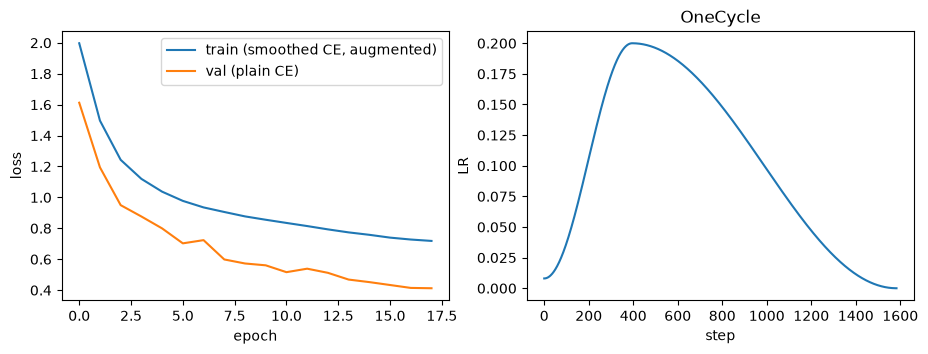

In [8]:
# 7. TEST (once) + CURVES. `test_loss, test_acc = evaluate(model, X_test, y_test)`. Per-class test accuracy.
#    Plot: (left) train vs val loss per epoch (train loss includes label smoothing + augmentation: say why it can sit
#    ABOVE val loss), (right) the LR schedule `lrs`.
test_loss, test_acc = evaluate(model, X_test, y_test)
print(f"test loss {test_loss:.3f} acc {test_acc:.4f}")
model.eval()
with torch.no_grad(), torch.autocast(**AMP):
    pred = torch.cat([model(X_test[k:k + 2000].contiguous(memory_format=torch.channels_last)).argmax(1) for k in range(0, 10000, 2000)])
for c in range(10):
    print(f"{CLASSES[c]:6s} {(pred[y_test == c] == c).float().mean():.3f}", end="  " if c % 5 < 4 else "\n")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history["train_loss"], label="train (smoothed CE, augmented)")
ax[0].plot(history["val_loss"], label="val (plain CE)")
ax[0].set(xlabel="epoch", ylabel="loss"); ax[0].legend()
ax[1].plot(lrs); ax[1].set(xlabel="step", ylabel="LR", title="OneCycle")
plt.show()

## Self-check
Expects: `mean`, `std`, `X_train`, `augment`, `model`, `make_model`, `evaluate`, `init_loss`, `overfit_loss`,
`history`, `lrs`, `best_state`, `best_acc`, `train_seconds`, `test_acc`.

In [9]:
check_close("per-channel train mean ~ 0", X_train[:20000].mean((0, 2, 3)), torch.zeros(3), atol=0.02)
check("mean/std are per channel", tuple(mean.shape) == (1, 3, 1, 1) and tuple(std.shape) == (1, 3, 1, 1))
kinds = {type(m) for m in model.modules()}
check("model has Conv2d, BatchNorm2d and pooling", nn.Conv2d in kinds and nn.BatchNorm2d in kinds and
      any(issubclass(k, (nn.MaxPool2d, nn.AvgPool2d, nn.AdaptiveMaxPool2d, nn.AdaptiveAvgPool2d)) for k in kinds))
check("no Softmax in model", not any(issubclass(k, (nn.Softmax, nn.LogSoftmax)) for k in kinds))
xa = X_train[:1].repeat(64, 1, 1, 1)
aug = augment(xa)
check("augment keeps shape", aug.shape == xa.shape)
check("augment is random PER IMAGE", (aug - aug[:1]).abs().flatten(1).amax(1).gt(1e-6).sum().item() > 32,
      "identical inputs should get different crops/flips within one batch")
check("augment actually changes images", not torch.allclose(augment(X_train[:16]), X_train[:16]))
check("evaluation is deterministic (no augmentation / dropout / BN updates in eval)",
      evaluate(model, X_val[:2000], y_val[:2000]) == evaluate(model, X_val[:2000], y_val[:2000]))
check("initial loss ~ ln 10", abs(init_loss - math.log(10)) < 0.3, f"got {init_loss:.3f}")
check("can overfit one batch", overfit_loss < 0.05, f"got {overfit_loss:.4f}")
check("LR schedule warms up then anneals", max(lrs) > 1.5 * lrs[0] and lrs[-1] < 0.1 * max(lrs),
      f"start {lrs[0]:.3g}, max {max(lrs):.3g}, end {lrs[-1]:.3g}")
check_close("best checkpoint restored (val acc == best)", evaluate(model, X_val, y_val)[1], best_acc, atol=2e-3)
check("history per epoch", len(history["val_acc"]) == len(history["train_loss"]) > 0)
check("trained within ~4 minutes", train_seconds < 240, f"{train_seconds:.0f}s")
check("test accuracy >= 0.80", test_acc >= 0.80, f"got {test_acc:.3f}")

ok  per-channel train mean ~ 0
ok  mean/std are per channel
ok  model has Conv2d, BatchNorm2d and pooling
ok  no Softmax in model
ok  augment keeps shape
ok  augment is random PER IMAGE
ok  augment actually changes images
ok  evaluation is deterministic (no augmentation / dropout / BN updates in eval)
ok  initial loss ~ ln 10
ok  can overfit one batch
ok  LR schedule warms up then anneals
ok  best checkpoint restored (val acc == best)
ok  history per epoch
ok  trained within ~4 minutes
ok  test accuracy >= 0.80


## Say it out loud (P3)
1. What does BatchNorm do in train vs eval mode? What breaks if you evaluate in train mode, or train with batch size 2?
2. Why is the conv bias disabled before BatchNorm?
3. Why augment only the training set? Is horizontal flip always label-preserving (think digits, text, left/right)?
4. OneCycle: what happens in each phase and why does a large peak LR help? Why step the scheduler per batch here?
5. Early stopping with OneCycle: why does it rarely trigger, and what does "keep the best checkpoint" buy instead?
6. Why can the train loss sit *above* the val loss in the plot? Is that underfitting?
7. What made this run take about a minute, and what would the bottleneck be with a standard `DataLoader` and PIL transforms?
8. How would you get from ~90 % to 94 %+ (name three things)?

<details><summary>Model answers</summary>

1. In train mode BN normalizes with the batch mean/var and updates running estimates (EMA, momentum 0.1). In
   eval mode it uses the running estimates, so the output doesn't depend on the rest of the batch. Evaluating in
   train mode makes predictions batch-dependent and also corrupts the running stats with val data. With tiny
   batches (2) the batch statistics are very noisy. GroupNorm/LayerNorm avoid that.
2. BN subtracts the per-channel mean, so a constant bias is cancelled exactly. BN's own β provides the shift.
   Keeping the conv bias only wastes parameters (and weight decay).
3. Augmentation encodes invariances we want at train time. At eval we want the deterministic, unaltered input,
   though test-time augmentation that averages logits over flips can help (airbench uses it). Flip is
   label-preserving for natural objects in CIFAR, but not for digits/text (a mirrored "2" isn't a 2) or for tasks
   where left/right matters.
4. The LR rises over the first 25 % of steps from max_lr/25 to max_lr, then anneals to max_lr/(25·10⁴). Both
   phases use cosine by default (PyTorch defaults `div_factor=25`, `final_div_factor=1e4`, `anneal_strategy="cos"`). Warm-up avoids early instability while BN
   statistics and weights are poorly scaled. The large LR adds regularizing noise and moves fast. The final low-LR
   phase settles into a minimum (Smith & Topin 2017). OneCycle is defined over `total_steps`, so it must be
   stepped per batch.
5. Val accuracy keeps improving until the LR has annealed: the biggest gains come at the end of the schedule. So
   the patience counter rarely runs out. Keeping the best-val checkpoint (retrospective selection, as in the
   tuning playbook) guards against a late regression at no cost. To actually use early stopping as a budget
   saver, pick a shorter schedule instead of cutting a long one.
6. The train loss is measured on augmented images with label smoothing 0.1. Smoothing alone puts a floor of
   about 0.5 nats under the loss, even for a perfect classifier, while val uses plain CE on clean images.
   Compare accuracies, or evaluate the train set without augmentation, to diagnose under/overfitting.
7. All 45k images sit on the GPU (about 0.55 GB in fp32), so augmentation is a few tensor ops and there is no
   host→device copy. bf16 autocast + channels_last make the convs use tensor cores. With PIL + `ToTensor` +
   `RandomCrop` in DataLoader workers, CPU decoding/augmentation and the copy become the bottleneck (several
   seconds per epoch even with workers). Use `pin_memory`, more workers, or GPU-side augmentation.
8. A ResNet-style net with residual connections (ResNet-9/18), longer training (e.g. 50+ epochs), test-time
   flip-averaging, more augmentation (Cutout), EMA/Lookahead of weights, and tuned label smoothing. Airbench stacks
   most of these plus whitening-initialized first-layer convs to hit 94 % in seconds.
</details>

In [10]:
s.finish(lookups=0, score=None, notes="")  # score: 1-5 self-rating; notes: what tripped you up

[P2.6] done in 0.8 min (within target 35 min)


0.8461349129676818